#### 데이터 누수
- 예측 시점에는 사용할 수 없는 정보
<br> -> 시험점수 데이터에 합격여부 컬럼이 있다면 <- 합격여부는 데이터 누수일 가능성이 있다.

#### ARIMA
- 자기회귀 차수 p : 과거 시차의 범위를 정하는 값
<BR> -> 월별 ARIMA(2, 0, 0)이면 7월을 설명할 때 6월과 5월 매출을 사용하겠다는 의미

- 차분 차수 d : ARIMA에서 차분을 몇 번 적용할 지 나타내는 값
<BR> -> d = 0(차분 x), d= 1(1차 차분), d=2(2차 차분)

- 이동 평균 차수 q : 과거 충격의 시차 범위를 정하는 값
<br> -> 월별 q=2라면 7월을 설명할 때 6월과 5월의 추정 오차를 반영하겠다.

- ARIMA
<BR> -> 차분 및 자기회귀 및 이동 평균 요소를 결합한 시계열 모델
<BR> -> ARIMA(2, 1, 1)은 매출을 한번 차분 한 뒤 최근 두 변화량과 직전 오차를 활용하여 모델링 하겠다는 뜻


# 2장 2강: 시계열 데이터 모델링과 예측

## 실습 목표

이번 실습에서는 **Bike Sharing Demand** 데이터를 이용하여 시계열 예측의 기본 흐름을 연습합니다.

- 시간 순서를 유지하면서 **Train / Test 데이터**를 분리합니다.
- **AR, I, MA**가 무엇을 의미하는지 확인합니다.
- **ARIMA(2, 1, 1)** 모델을 학습합니다.
- Test 기간의 미래 값을 예측합니다.
- 실제값과 예측값을 비교합니다.
- **MAE, RMSE**를 이용해 예측 성능을 평가합니다.

> 이 실습에서는 2장 2강 교안에 나온 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- statsmodels
- scikit-learn
- 데이터: `Bike_Sharing_Demand.csv`

### 주요 컬럼

| 컬럼 | 의미 |
|---|---|
| `datetime` | 자전거 대여 기록 시각 |
| `casual` | 비등록 사용자 대여 수 |
| `registered` | 등록 사용자 대여 수 |
| `count` | 전체 자전거 대여 수 |

이번 강에서는 월별 대여량 `count`를 시계열로 사용합니다.

## 실습 준비

다음 순서로 데이터를 준비합니다.

1. 데이터 불러오기
2. `datetime` 자료형 확인
3. 결측치 확인
4. `datetime`을 날짜/시간 자료형으로 변환
5. 시간 순서대로 정렬
6. 월별 대여량 `count` 준비

> 월별 집계 코드는 시계열 모델링을 위한 준비 코드로 제공됩니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

bike = pd.read_csv("Bike_Sharing_Demand.csv")

print("데이터 크기:", bike.shape)
display(bike.head())

print("\n[자료형]")
display(bike[["datetime", "count"]].dtypes.to_frame("dtype"))

print("\n[결측치]")
display(bike[["datetime", "count"]].isna().sum().to_frame("missing"))

데이터 크기: (10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1



[자료형]


,dtype
datetime,str
count,int64



[결측치]


,missing
datetime,0
count,0


In [2]:
bike["datetime"] = pd.to_datetime(bike["datetime"])
bike = bike.sort_values("datetime").reset_index(drop=True)

bike["month"] = (
    bike["datetime"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly = (
    bike.groupby("month", as_index=False)["count"]
    .sum()
)

monthly = monthly.set_index("month")

print("월별 데이터 개수:", len(monthly))
display(monthly.head())
display(monthly.tail())

월별 데이터 개수: 24


,count
month,
2011-01-01,23552
2011-02-01,32844
2011-03-01,38735
2011-04-01,50517
2011-05-01,79713


,count
month,
2012-08-01,130220
2012-09-01,133425
2012-10-01,127912
2012-11-01,105551
2012-12-01,98977


---

# 필수 1. 시간 순서를 유지한 Train / Test 분리

## 배경

시계열 데이터에서는 데이터를 무작위로 섞으면 미래 시점의 데이터가 Train에 포함될 수 있습니다.

따라서 **과거 데이터를 Train**, **그 이후 데이터를 Test**로 사용해야 합니다.

이번 실습에서는 월별 대여량의 **마지막 6개월을 Test 데이터**로 사용합니다.

## 문제 1. Train / Test 데이터를 분리하세요.

### 요구사항

1. `monthly`의 마지막 6개 행을 Test 데이터로 사용합니다.
2. 나머지 데이터를 Train 데이터로 사용합니다.
3. Train과 Test의 시작일과 종료일을 출력합니다.
4. Train과 Test를 같은 그래프에 표시합니다.

### 확인 포인트

- 시간 순서를 유지했는가?
- Test 데이터가 Train 데이터보다 뒤의 기간인가?
- 무작위 분리를 사용하지 않았는가?

Train 기간: 2011-01-01 00:00:00 ~ 2012-06-01 00:00:00
Test 기간: 2012-07-01 00:00:00 ~ 2012-12-01 00:00:00


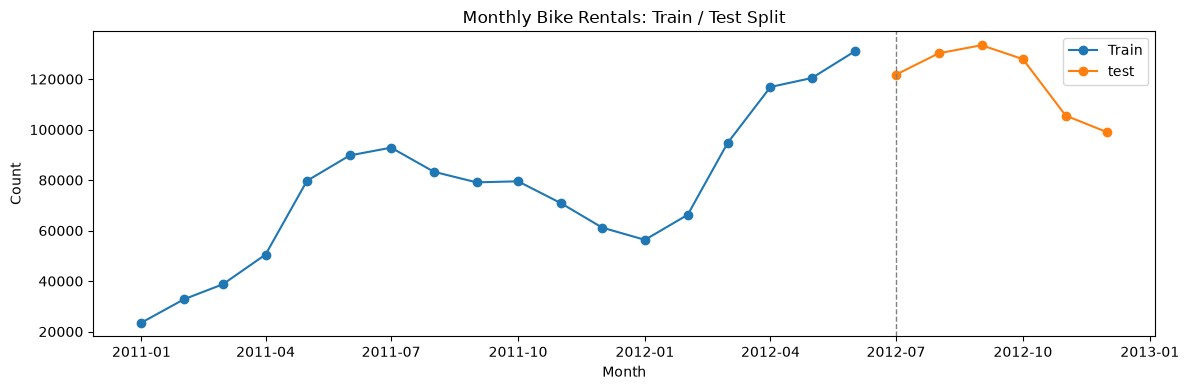

In [3]:
# TODO
# monthly 데이터를 Train / Test로 분리하세요.
train = monthly.iloc[:-6] # 마지막 6개 행 제외하고 선택
test = monthly.iloc[-6:] # 마지막 6개 행 부터 끝까지 선택

print(f'Train 기간: {train.index.min()} ~ {train.index.max()}')

print(f'Test 기간: {test.index.min()} ~ {test.index.max()}')

plt.figure(figsize=(12,4))
plt.plot(train.index, train['count'], marker='o', label='Train')
plt.plot(test.index, test['count'], marker='o', label='test')
plt.axvline(test.index[0], color='gray', linestyle='--', linewidth=1)
plt.title('Monthly Bike Rentals: Train / Test Split')
plt.xlabel('Month')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()


- 예측 시점은 2012년 6월까지를 알고 있는 상태로 가정
- 2012년 12월까지의 데이터가 존재하더라도 시계열에서 예측 시점에는 7월 ~ 12월 데이터를 모르는 것 처럼 남겨둔다.

- 18개월은 18개의 관측값일 뿐 18개월 치의 시간별 표본을 의미하지 않음
- 해석: 월별 관측 합계(총 기간) 24개우러 중 앞서 18개월을 train 마지막 6개월을 test로 분리
<br> -> 2011년 1월 ~ 2012년 6월까지의 정보를 토대로 2012년 7월부터 2012년 월까지를 예측하겠다.


### Q1. 시계열 데이터에서 무작위로 Train / Test를 분리하면 안 되는 이유는 무엇인가요?

**답변:**  
<br>-> 시계열 데이터는 순서가 매우 중요하다.
<br> -> 무작위로 섞게 되면 시간의 흐름을 알 수가 없고 미래 시점 값이 Train에 포함될 수 있다.

---

# 필수 2. ARIMA 모델 학습과 미래 값 예측

## 배경

ARIMA는 다음 세 가지 요소로 구성됩니다.

- **AR(p)**: 과거의 실제 값을 몇 개 사용할 것인가?
- **I(d)**: 차분을 몇 번 적용할 것인가?
- **MA(q)**: 과거의 예측 오차를 몇 개 사용할 것인가?

이번 실습에서는 교안과 동일하게 `ARIMA(2, 1, 1)`을 사용합니다.

## 문제 1. ARIMA(2, 1, 1)의 의미를 설명하세요.

### 요구사항

다음 세 값을 각각 설명합니다.

- `p = 2`
- `d = 1`
- `q = 1`

### Q2. 각각 무엇을 의미하나요?

**답변:**  
여기에 작성하세요.
- p = 2 라는 것의 의미 : 1차 차분한 시계열의 과거 2개의 시점 값을 활용하겠다.
- d =1 라는 것의 의미 : 1차 차분을 적용하겠다.
- q = 1 라는 것의 의미: 과거 1개의 시점의 예측 오차를 활용하겠다.

## 문제 2. Train 데이터로 ARIMA 모델을 학습하세요.

### 요구사항

1. `statsmodels.tsa.arima.model`에서 `ARIMA`를 불러옵니다.
2. Train 데이터의 `count`를 사용합니다.
3. `order=(2, 1, 1)`을 지정합니다.
4. `fit()`으로 모델을 학습합니다.

### 확인 포인트

- Test 데이터를 학습에 사용하지 않았는가?
- `order=(p, d, q)`의 순서를 알고 있는가?

In [4]:
# TODO
# ARIMA(2, 1, 1) 모델을 생성하고 학습하세요.
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(train['count'],order=(2,1,1))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  count   No. Observations:                   18
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -180.476
Date:                Thu, 01 Oct 2026   AIC                            368.953
Time:                        14:27:31   BIC                            372.285
Sample:                    01-01-2011   HQIC                           369.284
                         - 06-01-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5770      0.932      0.619      0.536      -1.249       2.403
ar.L2         -0.1038      0.541     -0.192      0.848      -1.165       0.957
ma.L1          0.2235      1.001      0.223      0.8

c:\DS_practice\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\DS_practice\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\DS_practice\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


변수로 count 하겠다. 과찰된 값은 18개월이고, model은 arima(2,1,1)

### 상단 기본 정보
- Dep.Variable -> count : 학습 대상으로 사용한 월별 관측 대여량 합계
- No.Observation -> 18 : 입력한 Train의 관측값 개수
- Model -> ARIMA(2,1,1) : 지정한 p,d,q의 구조
- Sample -> 2011-01 ~ 2012-06 : 학습에 사용한 기간 범위
- Log Likelihood -> -180: 추정한 모형이 관측자룔르 설명하는 우도를 로그로 요약한 값
- AIC / BIC / HQIC -> 368, 372, 369 : 적합도와 모형 복잡도를 함께 고려하는 정도

- ar.L1 -> 0.577: 직전 시점의 차분값에 적용되는 자기회귀 가중치
- ar.L2 -> -0.103 : 두 시점 전 차분값에 적용되는 자기회귀 가중치
- ma.L1 -> 0.223 : 직전 시점의 오차 및 충격에 적용되는 가중치
- sigma2 -> 약 8.347 * 10의 7제곱 : 모형에서 추정한 오차의 분산

### 하단 기본 정보 
- coef -> 추정 계수 : 모형에 들어가는 가중치나 분산 추정값
- std err -> 추정 표준오차 : 계수 추정 불확실성에 관한 값
- z -> 계수, 표준오차에 의한 검정통계량: 적절한 추론 조건에서 계수가 0이라는 가설을 판단하는 데 사용
- P>|z|
- [0.025, 0.975] -> 계수 명목상 95%의 신뢰구간
===================================================
- ar.L1          0.5770      0.932      0.619      0.536      -1.249       2.403
- 표에서 ar.L1을 해석하는 방법 : 계수는 0.57, 표준오차는 0.93, Z는 0.61, p-value는 0.53, 95%
- 신뢰구간 -1.2~2.4
- 해석: 추정 계수가 양수인 것으로 확인되지만, 표준오차가 계수보다 큰 경우, 신뢰구간도 음수에서부터 양수로 비교적 넓게 분포되어 있음
- 따라서 직전 변화량의 양의 가중치가 추정되어 있음
- 한줄 요약: 이 데이터 예측하기 어려움

- Ljung-Box(L1) / Prob(Q) : Q 약 0.00 / 0.95 -> 표시된 1시차의 잔차 자기상관에 대한 진단
- 0.95는 0.05보다 크기 때문에 귀무가설을 기각하지 못함
- 귀무가설은 검사한 시차까지 잔차의 자기상관이 없다. (이를 기각하지 못함)

- Jarque-Bera / Prob(JB): 0.81 / 0.67 -> 잔차의 정규성에 대한 진단
- 0.67은 0.05보다 크기 때문에 귀무가설을 기각하지 못함
- 귀무가설은 잔차가 정규 분포를 따른다. <- 이를 기각하지 못함

- Heteroskedasticity / Prob(H) : 1.07 -> 오차의 크기가 시간에 따라 달라지는 지?
- 초반에는 오차가 +-10 정도 후반에는 +-100정도로 시간이 지남에 따라 오차의 불확실성이 커진다.

- Skew: 0.47 -> 오차의 분포가 어느 방향으로 대칭 또는 비대칭을 이루고 있나요?
- skew를 왜도라고 부르는 데 0에 가까울수록 좌우 대칭모양이다.
- 지금은 0.41로 양의 대칭을 보이는 즉 양수방향으로 꼬리가 긴 분포

- Kurtosis : 2.30 -> 3을 기준으로 정규분포에서 얼마나 극단적인 값들이 분포가 되어 있을까?
- Kurtosis를 첨도라고 부르는 데, 이 모델링 기준에서는 첨도가 3인데
- 3을 기준으로 크거나 작은 극단값들이 얼마나 있는지 

## 문제 3. Test 기간만큼 미래 값을 예측하세요.

### 요구사항

1. `forecast()`를 사용합니다.
2. `steps=len(test)`로 Test 기간과 같은 개수만큼 예측합니다.
3. 예측값의 인덱스를 Test 데이터의 인덱스와 동일하게 설정합니다.
4. `actual`, `predicted` 컬럼을 가진 DataFrame을 만듭니다.
5. 실제값과 예측값을 같은 그래프에 표시합니다.

### 확인 포인트

- Train 마지막 시점 이후의 값을 예측했는가?
- Test 길이와 예측값 개수가 같은가?
- Actual과 Predicted를 구분했는가?

,actual,predicted
month,,
2012-07-01,121769,139405.880749
2012-08-01,130220,143188.734859
2012-09-01,133425,144494.520944
2012-10-01,127912,144855.327175
2012-11-01,105551,144927.980297
2012-12-01,98977,144932.451482


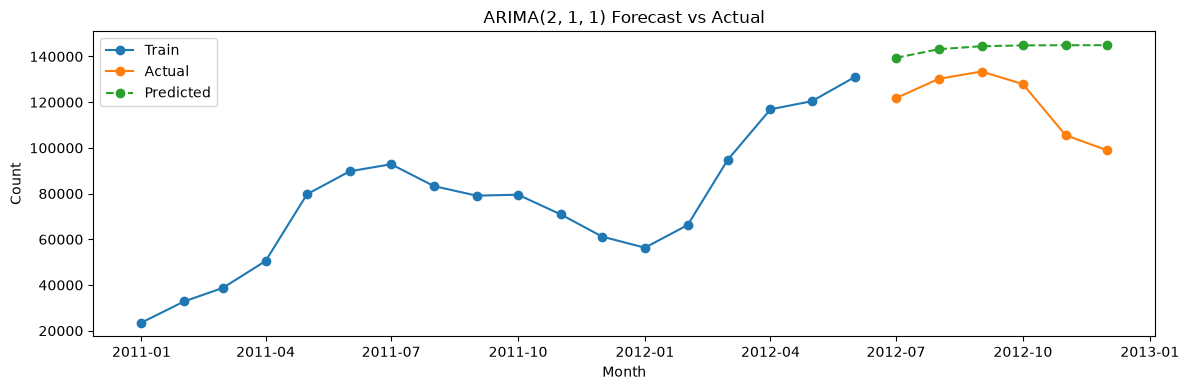

In [6]:
# TODO
# Test 기간만큼 예측하고 Actual / Predicted를 비교하세요.
# 1~2. Test 기간만큼 예측
forecast = model_fit.forecast(steps=len(test))

# 3. 예측값의 인덱스를 Test 인덱스와 동일하게 설정
forecast.index = test.index

# 4. 실제값과 예측값을 담은 DataFrame
result_df = pd.DataFrame({
    "actual": test["count"],
    "predicted": forecast
})
display(result_df)

# 5. 실제값과 예측값 시각화
plt.figure(figsize=(12, 4))
plt.plot(train.index, train["count"], marker="o", label="Train")
plt.plot(result_df.index, result_df["actual"], marker="o", label="Actual")
plt.plot(result_df.index, result_df["predicted"], marker="o", linestyle="--", label="Predicted")
plt.title("ARIMA(2, 1, 1) Forecast vs Actual")
plt.xlabel("Month")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()



- 2017-07 : 실제 관측 합계 121,769 / 예측 합계 139,405 -> 약 17,636건 과대 예측
- 2017-08 : 실제 관측 합계 130,220 / 예측 합계 143,188 -> 약 12,969건 과대 예측
- 2017-07 : 실제 관측 합계 133,425 / 예측 합계 144,494 -> 약 11,069건 과대 예측
- 과대 예측 하는 경향이 보임

- 해석: 2011년 1월 ~ 2012년 6월까지 18개월을 학습하여 향후 6개월을 예측했다.
- 예측값은 모든 Test 월에서 실제보다 높게 측정되었으며 오차가 큰편이였다.
- 정확하게 해석하기 위해서 추가적인 성능평가도 함께 확인해야한다.

### Q3. `steps=len(test)`는 무엇을 의미하나요?

**답변:**  
여기에 작성하세요.
- Test 데이터와 동일한 개수의 미래 시점을 예측한다는 의미
- 이번 모델링에서는 향후 6개월임

### Q4. Actual과 Predicted는 각각 무엇을 의미하나요?

**답변:**  
여기에 작성하세요.
- Actual : Test 기간에 실제로 관측된 자전거 대여량
- Predicted : Train 데이터만 학습한 ARIMA 모델이 주어진 Test 기간에 대해 예측한 값

---

# 과제 1. 정상성 진단을 반영한 ARIMA 예측과 예측 신뢰도 평가

## 배경

필수 1의 Train/Test 분리는 유지합니다. 과제에서는 Train 데이터의 정상성을 먼저 진단한 뒤 ARIMA의 차분 차수 d를 선택하여 모델을 다시 학습합니다. MAE·RMSE와 함께 **95% 예측 구간의 하한·상한**을 실제값과 비교합니다.

## 요구사항

1. 필수 1에서 만든 `train`, `test`를 사용합니다. 정상성 진단과 모델 설정에는 Train만 사용합니다.
2. Train의 `count`와 최근 3개 관측값의 이동평균을 그래프로 확인합니다. 원본에 ADF Test를 수행하고 검정통계량과 p-value를 출력합니다. 짧은 월별 자료이므로 이번 과제의 검정 설정은 `maxlag=1, regression="c", autolag="AIC"`로 통일합니다.
3. 유의수준 0.05에서 원본의 단위근 귀무가설을 기각하면 d=0을 우선 검토합니다. 기각하지 못하면 1차 차분한 Train에 같은 설정으로 ADF Test를 다시 수행하고 차분 그래프를 확인합니다. 차분 후 기각하면 d=1을 선택합니다. 차분 후에도 기각하지 못하면 추가 진단이 필요함을 명시하고, 이번 과제에서는 d=1을 잠정 설정하여 예측 과정과 한계를 함께 평가합니다. 선택 근거에 그래프 해석도 포함합니다.
4. **차분하지 않은 Train의 원본 `count`**를 `ARIMA(order=(2, d, 1))`에 전달해 학습합니다. 차분은 모델 내부에서 처리하므로 차분 데이터에 d=1을 다시 적용하지 않습니다. 필수 2의 모델·결과와 구분하여 과제용 변수를 사용합니다.
5. `get_forecast(steps=len(test))`로 Test 기간의 예측값과 95% 예측 구간을 구합니다. `predicted_mean`과 `conf_int(alpha=0.05)`를 활용합니다.
6. Test 날짜에 맞춰 `actual`, `predicted`, `lower_95`, `upper_95`를 가진 `task_result`를 만들고 출력합니다.
7. 과제 모델의 MAE·RMSE를 계산하고 의미를 설명합니다.
8. 실제값·예측값·95% 예측 구간을 같은 그래프에 표시합니다. 시점별 구간 폭과 실제값의 구간 포함 여부를 표에 추가하고, 구간 밖인 시점을 확인합니다.
9. 실제값과 구간의 비교 및 구간 폭을 근거로 예측 신뢰도를 해석합니다. 신뢰도가 낮다고 판단한 구간의 가능한 원인 또는 모델의 한계를 한 가지 이상 설명합니다. 구간 밖인 시점이 없더라도 구간 폭과 자료의 한계를 검토합니다.

> Test는 최종 평가에만 사용합니다. Test 결과를 보고 d나 다른 모델 설정을 다시 선택하지 않습니다. 월별 값은 제공된 CSV의 관측값 합계이며, 월 전체 날짜가 없으면 완전한 월간 총수요로 해석하지 않습니다.

### 확인 포인트

- Train만으로 정상성을 진단하고 d 선택 근거를 제시했는가?
- 1차 차분 후에도 귀무가설을 기각하지 못한 경우 잠정 모델의 한계를 밝혔는가?
- 원본 Train을 모델에 입력하여 이중 차분을 피했는가?
- MAE·RMSE와 실제값·예측값·예측 구간을 함께 확인했는가?
- 구간 밖 실제값과 구간 폭을 근거로 예측 신뢰도와 한계를 설명했는가?
- Q5~Q9에 모두 답했는가?


In [ ]:
# TODO
# Train 정상성 진단 → d 선택 → 과제용 ARIMA 학습
# → 점예측·95% 예측 구간 → MAE·RMSE → 신뢰도 및 한계 해석


### Q5. MAE는 어떻게 해석할 수 있나요?

**답변:**
여기에 작성하세요.


### Q6. RMSE가 MAE보다 큰 오차에 더 민감한 이유는 무엇인가요?

**답변:**
여기에 작성하세요.


### Q7. Train 데이터의 ADF 검정 결과와 그래프를 근거로 d를 어떻게 선택했나요? 정상성 판단에 남아 있는 한계는 무엇인가요?

**답변:**
여기에 작성하세요.


### Q8. Test 실제값이 95% 예측 구간 밖에 나타난 시점은 언제이며, 구간 폭은 시점별로 어떻게 달라지나요? 이를 근거로 예측 신뢰도를 설명하세요.

**답변:**
여기에 작성하세요.


### Q9. 예측 신뢰도가 낮다고 판단한 시점 또는 구간은 어디인가요? 가능한 원인이나 모델의 한계를 한 가지 이상 설명하세요.

**답변:**
여기에 작성하세요.


---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 시계열 Train/Test 분리에서 가장 중요한 원칙은 무엇인가요?
<BR> -> 시간 순서를 유지한다는 원칙

2. ARIMA의 `p`, `d`, `q`는 각각 무엇을 의미하나요?
<BR> -> p는 차분 후 시계열의 과거 값 개수
<br> -> d는 차분 횟수
<br> -> q는 사용할 과거 예측의 오차의 개수

3. `forecast(steps=6)`은 무엇을 의미하나요?
<br> -> Train의 마지막 시점 이후 6개의 미래 시점을 예측

4. Actual과 Predicted의 차이는 무엇인가요?
<br> -> 실제 Test값과 모델이 예측한 Predicted 값

5. MAE와 RMSE는 값이 클수록 좋은 지표인가요, 작을수록 좋은 지표인가요?
<br> -> 두 지표 모두 작을수록 실제값과 예측값의 차이가 작다.